# C5 · Quanto caixa está parado no estoque da indústria

**Pergunta:** quanto dinheiro as industriais de capital aberto liberariam se girassem o
estoque no ritmo do próprio setor — e quanto custa, por ano, manter esse excesso parado?

Fontes:
- **Demonstrações financeiras padronizadas (DFP) da CVM**, 2021 a 2025, balanço
  consolidado, e o cadastro de companhias abertas (setor de cada empresa). A mesma base
  do projeto C2.
- **Selic** acumulada no mês, anualizada (série 4189 do SGS do Banco Central), como
  custo de oportunidade do dinheiro parado.

## 1. Estoque, custo do produto vendido e setor

Mesmas regras do C2: só balanço consolidado, última versão entregue, setores industriais
e de extração, receita de pelo menos R$ 50 milhões, holdings e construção civil fora,
setores com menos de 5 empresas agrupados em "Demais industriais". Empresas em
recuperação judicial ficam marcadas e fora das medianas.

In [1]:
import zipfile, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

CONTAS = {'1.01.04': 'estoques', '3.01': 'receita', '3.02': 'cpv'}
partes = []
for ano in range(2021, 2026):
    z = zipfile.ZipFile(f'dados/dfp_cia_aberta_{ano}.zip')
    for dem in ['BPA', 'DRE']:
        d = pd.read_csv(z.open(f'dfp_cia_aberta_{dem}_con_{ano}.csv'), sep=';', encoding='latin-1', dtype=str)
        d = d[d.ORDEM_EXERC.str.startswith('ÚLT') & d.CD_CONTA.isin(CONTAS)].copy()
        d['VERSAO'] = d.VERSAO.astype(int)
        d = d[d.VERSAO == d.groupby('CD_CVM').VERSAO.transform('max')]
        d['valor'] = d.VL_CONTA.astype(float) * np.where(d.ESCALA_MOEDA == 'MIL', 1e3, 1)
        d['ano'] = ano
        partes.append(d[['CD_CVM', 'ano', 'CD_CONTA', 'DS_CONTA', 'valor']])
contas = pd.concat(partes)
contas['CD_CVM'] = contas.CD_CVM.astype(int)
plano_ok = contas[(contas.CD_CONTA == '1.01.04') & contas.DS_CONTA.str.startswith('Estoques')][['CD_CVM', 'ano']]
w = (contas.pivot_table(index=['CD_CVM', 'ano'], columns='CD_CONTA', values='valor', aggfunc='first')
     .rename(columns=CONTAS).reset_index().merge(plano_ok, on=['CD_CVM', 'ano']))

cad = pd.read_csv('dados/cad_cia_aberta.csv', sep=';', encoding='latin-1', dtype=str)
cad['CD_CVM'] = cad.CD_CVM.astype(int)
cad = cad.sort_values('DT_REG').drop_duplicates('CD_CVM', keep='last')
INDUSTRIA = ['Máquinas, Equipamentos, Veículos e Peças', 'Metalurgia e Siderurgia', 'Têxtil e Vestuário',
             'Alimentos', 'Agricultura (Açúcar, Álcool e Cana)', 'Farmacêutico e Higiene', 'Petróleo e Gás',
             'Petroquímicos e Borracha', 'Papel e Celulose', 'Extração Mineral', 'Bebidas e Fumo',
             'Outras Atividades Industriais', 'Embalagens']
w = w.merge(cad[['CD_CVM', 'DENOM_SOCIAL', 'DENOM_COMERC', 'SETOR_ATIV']], on='CD_CVM')
w = w[w.SETOR_ATIV.isin(INDUSTRIA)].copy()
w['cpv'] = -w.cpv
w = w[(w.receita >= 50e6) & (w.cpv > 0) & (w.estoques >= 0)].copy()
pequenos = w[w.ano == 2025].SETOR_ATIV.value_counts().loc[lambda s: s < 5].index
w['setor'] = np.where(w.SETOR_ATIV.isin(pequenos), 'Demais industriais', w.SETOR_ATIV)
w['rj'] = w.DENOM_SOCIAL.str.contains('RECUPERA', case=False)
print(f'{len(w):,} demonstrações · {w.CD_CVM.nunique()} empresas · {(w.ano == 2025).sum()} com balanço de 2025')

511 demonstrações · 110 empresas · 97 com balanço de 2025


## 2. Prazo de estoque e a meta do setor

**Prazo de estoque** = estoque de fim de ano ÷ custo do produto vendido × 365: quantos
dias de custo de produção estão parados no estoque.

**Meta:** o prazo da **mediana** do setor naquele ano (cenário principal) ou do
**quartil mais curto** (P25, cenário mais exigente). Empresas em recuperação judicial
não entram no cálculo da meta.

**Estoque acima da meta (R$)** = (prazo da empresa − prazo da meta) × custo do produto
vendido por dia. Empresa abaixo da meta conta zero — a conta não premia quem já está
enxuto, só mede o excesso de quem está acima.

In [2]:
w['prazo'] = w.estoques / w.cpv * 365
base = w[~w.rj]
metas = base.groupby(['setor', 'ano']).prazo.agg(mediana='median', p25=lambda s: s.quantile(.25), n='size').reset_index()
w = w.merge(metas, on=['setor', 'ano'], how='left')
for m in ['mediana', 'p25']:
    w[f'excesso_{m}'] = (w.prazo - w[m]).clip(lower=0) * w.cpv / 365
w['nome'] = w.DENOM_COMERC.where(w.DENOM_COMERC.notna() & (w.DENOM_COMERC.str.strip() != ''), w.DENOM_SOCIAL)
w['nome'] = (w.nome.str.replace(r'\s*-?\s*EM RECUPERA[ÇC][ÃA]O JUDICIAL', '', regex=True, case=False)
             .str.replace(r'\s+(S\.?/?A\.?|S\.A)$', '', regex=True, case=False).str.strip().str.title())
metas[metas.ano == 2025].round(1)

,setor,ano,mediana,p25,n
4,"Agricultura (Açúcar, Álcool e Cana)",2025,51.1,25.9,12
9,Alimentos,2025,35.7,31.6,13
14,Demais industriais,2025,87.5,59.6,10
19,Farmacêutico e Higiene,2025,186.2,157.0,6
24,Metalurgia e Siderurgia,2025,88.4,73.9,12
29,"Máquinas, Equipamentos, Veículos e Peças",2025,102.8,67.3,16
34,Petroquímicos e Borracha,2025,55.0,53.3,5
39,Petróleo e Gás,2025,56.4,36.5,6
44,Têxtil e Vestuário,2025,144.0,121.9,14


## 3. Selic: o custo de oportunidade do dinheiro parado

Cada real parado em estoque é um real que não está aplicado, nem abatendo dívida. A
Selic média do ano é a conta mais conservadora: armazenagem, seguro, perda e
obsolescência vêm **por cima** e não estão aqui.

In [3]:
selic = pd.DataFrame(json.load(open('dados/selic_4189.json')))
selic['ano'] = selic.data.str[-4:].astype(int)
selic['valor'] = selic.valor.astype(float)
SELIC = (selic.groupby('ano').valor.mean() / 100).round(4)
print((SELIC * 100).round(2).to_string())

ano
2021     4.42
2022    12.43
2023    13.20
2024    10.84
2025    14.32


## 4. Quanto está parado em 2025

In [4]:
a25 = w[(w.ano == 2025) & ~w.rj].copy()
EXC = a25.excesso_mediana.sum()
EXC_P25 = a25.excesso_p25.sum()
CUSTO = EXC * SELIC[2025]
acima = a25[a25.excesso_mediana > 0]
top5 = a25.excesso_mediana.nlargest(5).sum() / EXC
top10 = a25.excesso_mediana.nlargest(10).sum() / EXC
print(f'{len(a25)} industriais (fora de recuperação judicial) · estoque total R$ {a25.estoques.sum()/1e9:.1f} bi')
print(f'Estoque acima da mediana do próprio setor: R$ {EXC/1e9:.1f} bi, em {len(acima)} empresas')
print(f'Custo de oportunidade a Selic média de 2025 ({SELIC[2025]:.2%}): R$ {CUSTO/1e9:.2f} bi por ano')
print(f'Meta mais exigente (quartil mais curto do setor): R$ {EXC_P25/1e9:.1f} bi')
print(f'Concentração: as 5 maiores respondem por {top5:.0%} do excesso; as 10 maiores, por {top10:.0%}')
print(f'Sem as 5 maiores: R$ {(EXC - a25.excesso_mediana.nlargest(5).sum())/1e9:.1f} bi em {len(acima) - 5} empresas')

94 industriais (fora de recuperação judicial) · estoque total R$ 275.7 bi
Estoque acima da mediana do próprio setor: R$ 28.3 bi, em 46 empresas
Custo de oportunidade a Selic média de 2025 (14.32%): R$ 4.05 bi por ano
Meta mais exigente (quartil mais curto do setor): R$ 76.0 bi
Concentração: as 5 maiores respondem por 70% do excesso; as 10 maiores, por 83%
Sem as 5 maiores: R$ 8.5 bi em 41 empresas


**A empresa típica com excesso.** O total é dominado por poucas empresas grandes. Para
quem gere uma indústria média, a pergunta útil é outra: quando o estoque está acima do
setor, quantos dias a mais, e quanto isso pesa por real de custo?

In [5]:
acima = acima.assign(dias=acima.prazo - acima.mediana, por_100mi=acima.excesso_mediana / acima.cpv * 100e6)
DIAS_MED = acima.dias.median()
POR100 = acima.por_100mi.median()
print(f'Entre as {len(acima)} empresas acima da mediana do setor, a típica (mediana) tem {DIAS_MED:.0f} dias de estoque a mais')
print(f'= R$ {POR100/1e6:.1f} milhões parados a cada R$ 100 milhões de custo do produto vendido no ano,')
print(f'  que custam R$ {POR100*SELIC[2025]/1e6:.1f} milhões por ano à Selic de 2025.')

Entre as 46 empresas acima da mediana do setor, a típica (mediana) tem 31 dias de estoque a mais
= R$ 8.5 milhões parados a cada R$ 100 milhões de custo do produto vendido no ano,
  que custam R$ 1.2 milhões por ano à Selic de 2025.


## 5. Por setor e ao longo do tempo

In [6]:
setores = (a25.groupby('setor').agg(empresas=('prazo', 'size'), prazo_mediano=('mediana', 'first'),
                                    estoque=('estoques', 'sum'), excesso=('excesso_mediana', 'sum'))
           .assign(estoque=lambda x: (x.estoque / 1e9).round(1), excesso=lambda x: (x.excesso / 1e9).round(2))
           .sort_values('excesso', ascending=False))
print(setores.round(1).to_string())
print()
por_ano = w[~w.rj].groupby('ano').agg(excesso=('excesso_mediana', 'sum'))
por_ano['custo_selic'] = por_ano.excesso * SELIC.reindex(por_ano.index).values
print((por_ano / 1e9).round(2).to_string())

                                          empresas  prazo_mediano  estoque  excesso
setor                                                                              
Máquinas, Equipamentos, Veículos e Peças        16          102.8     31.6      9.9
Petróleo e Gás                                   6           56.4     50.6      6.5
Agricultura (Açúcar, Álcool e Cana)             12           51.1     13.3      3.5
Alimentos                                       13           35.7     56.9      3.2
Metalurgia e Siderurgia                         12           88.4     34.5      2.8
Demais industriais                              10           87.5     59.8      1.0
Farmacêutico e Higiene                           6          186.2      8.9      0.6
Petroquímicos e Borracha                         5           55.0     11.8      0.4
Têxtil e Vestuário                              14          144.0      8.2      0.4

      excesso  custo_selic
ano                       
2021    34.68        

## 6. O número

In [7]:
print(f'R$ {EXC/1e9:.1f} bilhões: o estoque que as industriais de capital aberto mantêm acima da mediana do próprio setor (2025).')
print(f'À Selic média do ano, R$ {CUSTO/1e9:.1f} bilhões por ano de custo de oportunidade — antes de armazenagem, seguro e perda.')
print(f'Para a empresa típica acima do setor: {DIAS_MED:.0f} dias a mais, R$ {POR100/1e6:.1f} mi parados a cada R$ 100 mi de custo.')

R$ 28.3 bilhões: o estoque que as industriais de capital aberto mantêm acima da mediana do próprio setor (2025).
À Selic média do ano, R$ 4.0 bilhões por ano de custo de oportunidade — antes de armazenagem, seguro e perda.
Para a empresa típica acima do setor: 31 dias a mais, R$ 8.5 mi parados a cada R$ 100 mi de custo.


## 7. Dados do painel e capa

In [8]:
from pathlib import Path
Path('painel').mkdir(exist_ok=True)
linhas = []
for r in w.sort_values(['setor', 'nome', 'ano']).itertuples():
    linhas.append({'id': int(r.CD_CVM), 'nome': r.nome, 'setor': r.setor, 'ano': int(r.ano), 'rj': bool(r.rj),
                   'estoque': round(r.estoques / 1e6, 1), 'cpv': round(r.cpv / 1e6, 1), 'receita': round(r.receita / 1e6, 1)})
exp = {'linhas': linhas, 'selic': {int(k): float(v) for k, v in SELIC.items()},
       'resumo': {'excesso': round(float(EXC) / 1e9, 1), 'custo': round(float(CUSTO) / 1e9, 1), 'top5': round(float(top5), 3),
                  'dias_med': round(float(DIAS_MED)), 'por100': round(float(POR100) / 1e6, 1), 'empresas': int(len(a25))}}
Path('painel/dados.js').write_text('window.ESTOQUE = ' + json.dumps(exp, ensure_ascii=False, separators=(',', ':')) + ';\n', encoding='utf-8')
print(f"painel/dados.js · {Path('painel/dados.js').stat().st_size/1e3:.0f} KB · {len(linhas)} linhas")

painel/dados.js · 73 KB · 511 linhas


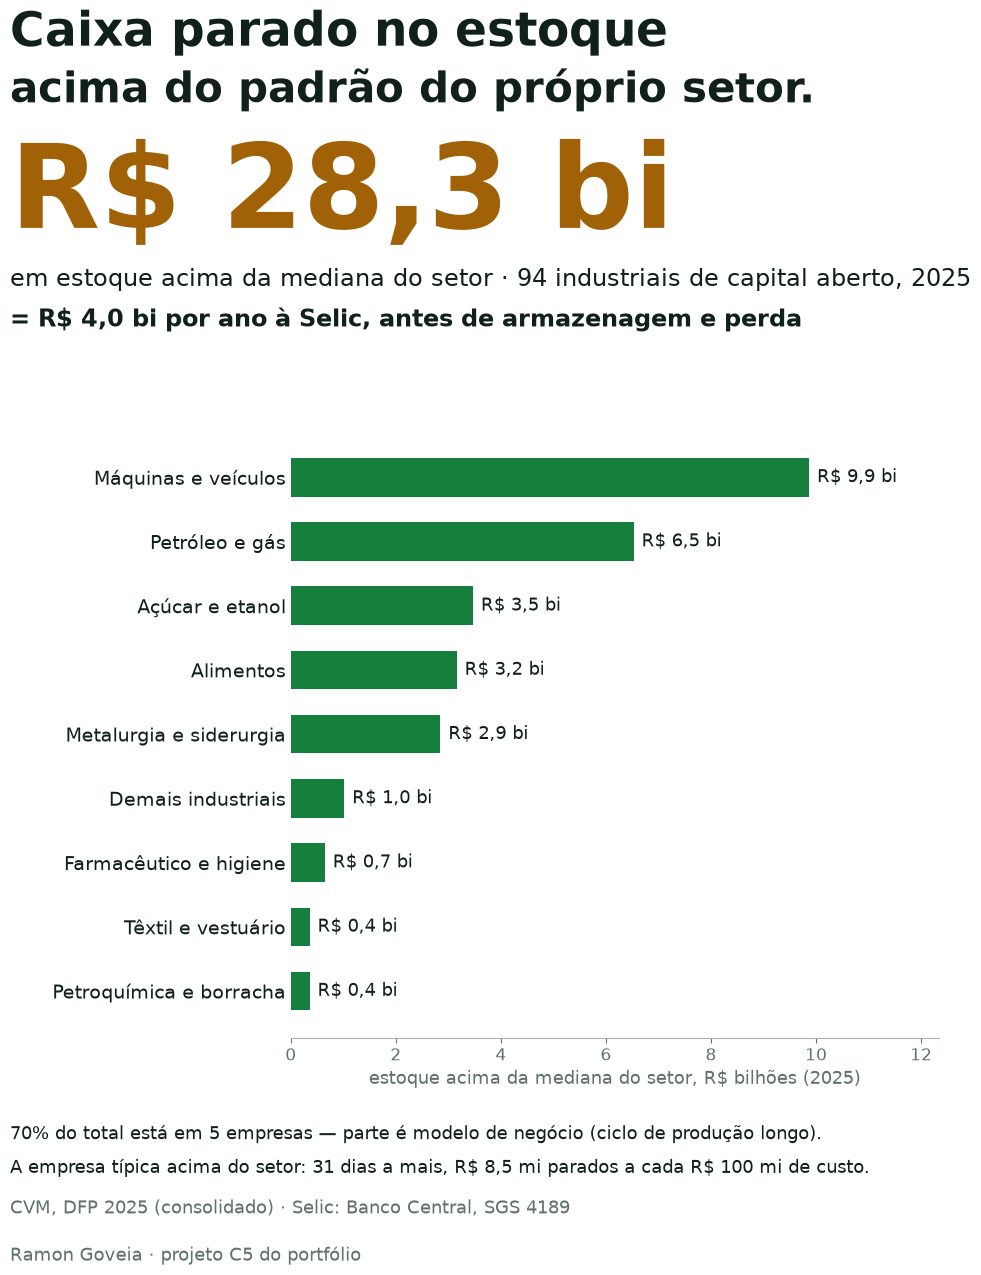

In [9]:
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['text.parse_math'] = False
# paleta própria do C5 (caixa e dinheiro): verde para as barras, dourado escuro para o valor
TINTA, AZUL, METRICA, CINZA, CLARO = '#10201a', '#15803d', '#a16207', '#5f7469', '#a3b8ad'
virg = lambda v, d=1: f'{v:.{d}f}'.replace('.', ',')
CURTO = {'Máquinas, Equipamentos, Veículos e Peças': 'Máquinas e veículos', 'Agricultura (Açúcar, Álcool e Cana)': 'Açúcar e etanol',
         'Metalurgia e Siderurgia': 'Metalurgia e siderurgia', 'Farmacêutico e Higiene': 'Farmacêutico e higiene',
         'Petroquímicos e Borracha': 'Petroquímica e borracha', 'Têxtil e Vestuário': 'Têxtil e vestuário', 'Petróleo e Gás': 'Petróleo e gás'}
fig = plt.figure(figsize=(10.8, 13.5), dpi=100)
fig.patch.set_facecolor('white')
fig.text(.07, .935, 'Caixa parado no estoque', fontsize=34, weight='bold', color=TINTA)
fig.text(.07, .893, 'acima do padrão do próprio setor.', fontsize=30, weight='bold', color=TINTA)
fig.text(.07, .80, f'R$ {virg(EXC/1e9)} bi', fontsize=84, weight='bold', color=METRICA)
fig.text(.07, .757, f'em estoque acima da mediana do setor · {len(a25)} industriais de capital aberto, 2025', fontsize=17, color=TINTA)
fig.text(.07, .727, f'= R$ {virg(CUSTO/1e9)} bi por ano à Selic, antes de armazenagem e perda', fontsize=17, color=TINTA, weight='bold')
ax = fig.add_axes([.33, .2, .6, .45])
s = setores.sort_values('excesso')
ax.barh([CURTO.get(i, i) for i in s.index], s.excesso, color=AZUL, height=.6)
for i, v in enumerate(s.excesso):
    ax.text(v + .15, i, f'R$ {virg(v)} bi', va='center', fontsize=13, color=TINTA)
ax.set_xlabel('estoque acima da mediana do setor, R$ bilhões (2025)', fontsize=13, color=CINZA)
ax.tick_params(axis='y', labelsize=14, colors=TINTA, length=0); ax.tick_params(axis='x', colors=CINZA, labelsize=12)
for sp in ['top', 'right', 'left']: ax.spines[sp].set_visible(False)
ax.spines['bottom'].set_color(CLARO); ax.set_xlim(0, s.excesso.max() * 1.25)
fig.text(.07, .125, f'{top5:.0%} do total está em 5 empresas — parte é modelo de negócio (ciclo de produção longo).'.replace('.', ',', 0), fontsize=13, color=TINTA)
fig.text(.07, .1, f'A empresa típica acima do setor: {DIAS_MED:.0f} dias a mais, R$ {virg(POR100/1e6)} mi parados a cada R$ 100 mi de custo.', fontsize=13, color=TINTA)
fig.text(.07, .07, 'CVM, DFP 2025 (consolidado) · Selic: Banco Central, SGS 4189', fontsize=13, color=CINZA)
fig.text(.07, .035, 'Ramon Goveia · projeto C5 do portfólio', fontsize=13, color=CINZA)
fig.savefig('capa.png', dpi=100, facecolor='white')
plt.show()

## 8. Limitações

- **Estoque alto não é, por si, desperdício.** Ciclo de produção longo (aeronave,
  safra), estoque estratégico de importação, sazonalidade e mudança de preço de insumo
  explicam parte do excesso. A conta mostra onde perguntar, não o que cortar.
- **O total é concentrado.** Poucas empresas grandes respondem pela maior parte; o
  número da empresa típica (mediana) diz mais sobre uma indústria média.
- **O setor da CVM é amplo.** "Máquinas, Equipamentos, Veículos e Peças" junta
  fabricante de aeronave, montadora e autopeça; "Petróleo e Gás" junta produtor e
  refinador. A mediana de setor heterogêneo é uma régua imperfeita.
- **Saldo de 31/12.** O estoque do balanço é uma foto do fim do ano, não a média.
- **A DFP padronizada não separa matéria-prima, produto em processo e acabado.** O
  diagnóstico de onde está o excesso exige as notas explicativas de cada empresa.
- **Selic é só o custo de oportunidade.** Armazenagem, seguro, perda e obsolescência
  ficam de fora — o custo real de carregar estoque é maior.
- **Só capital aberto.** As maiores; a média e a pequena indústria não estão aqui.